#**Multivariate Statistical Analysis Assignment**

**Name**: Taha Khan

**Student Number**: R00260537





---



**Acknowledgements**

This work was completed as part of the **Multivariate Modelling (STAT9014 31544)** module. I would like to acknowledge my lecturer, Aidan Duggan, for his teaching and for providing lecture slides and materials that were very helpful in understanding the concepts and techniques used in this assignment.



---



**Project Description**

This project applies multivariate statistical analysis to investigate the structure of diagnostic measurements in the Breast Cancer Wisconsin (Diagnostic) dataset using Principal Component Analysis (PCA). The dataset contains multiple continuous features extracted from digitized images of breast cell nuclei, making it suitable for dimensionality reduction.

The aim is to reduce the high-dimensional feature space into a smaller number of interpretable principal components, identify latent patterns among correlated variables, and examine how these components relate to distinguishing benign and malignant tumors. Through exploratory analysis, variance decomposition, and component interpretation, this study seeks to demonstrate how PCA can simplify complex biomedical data while preserving meaningful diagnostic information.

Dataset to run this project can be downloaded from the link given below

https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic



---



**Research Objective**

To use Principal Component Analysis to reduce correlated diagnostic variables into a smaller set of principal components and identify the underlying factors associated with differentiation between benign and malignant breast tumors.



---



**Hypothesis**

The diagnostic characteristics of breast tumors are driven by a small number of underlying latent factors, and a limited number of principal components will explain a substantial proportion of variability in the data while capturing patterns relevant to tumor classification.



---



**Why Multivariate Analysis is Appropriate**

Multivariate analysis is appropriate because this dataset contains numerous continuous diagnostic variables, many of which are correlated and jointly describe tumor morphology. Examining these variables individually would ignore interrelationships and may fail to reveal the broader structure underlying the data.

By analysing all variables simultaneously, multivariate methods can identify latent patterns, reduce redundancy, and provide a more holistic understanding of how combinations of diagnostic features relate to tumor behaviour. Given the complexity and dimensionality of the dataset, multivariate analysis is necessary to extract meaningful structure from the data.



---



**Why your chosen dimensionality reduction technique is suitable for addressing your objective?**


Principal Component Analysis (PCA) is suitable because the data contains many correlated continuous variables, creating redundancy that can make interpretation difficult. PCA reduces these variables into a smaller set of uncorrelated components while preserving most of the variation in the data.

This supports the research objective by identifying the main underlying factors influencing tumor characteristics, simplifying high-dimensional data, and making patterns related to benign and malignant cases easier to interpret. Tools such as scree plots, explained variance and component loadings also help justify the number of components retained and support meaningful interpretation.


**Section 0: Environment Setup and Library Imports**

In [1]:
!pip install factor_analyzer -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 kB 1.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
!pip install networkx

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import plotly.express as px
import networkx as nx
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.figsize'] = (10, 6)
OUT_DIR = "."
# Installing the factor analyzer library

from factor_analyzer import FactorAnalyzer

print("="*70)
print("SECTION 0: ENVIRONMENT SETUP COMPLETE")
print("Libraries loaded: numpy, pandas, matplotlib, seaborn, sklearn")
print("="*70)

SECTION 0: ENVIRONMENT SETUP COMPLETE
Libraries loaded: numpy, pandas, matplotlib, seaborn, sklearn


**Code Reproducibility**

In [4]:
np.random.seed(42)

**Section 1: Data Loading and Initial Exploration**

In [5]:
print("\n" + "="*70)
print("SECTION 1: DATA LOADING")
print("="*70)

# Loading dataset from CSV
df_raw = pd.read_csv("/content/breast cancer dataset.csv")

print(f"Dataset shape: {df_raw.shape}")
print(f"Total missing values: {df_raw.isnull().sum().sum()}")

# Show diagnosis distribution (change column name if needed)
print(f"Target distribution:\n{df_raw['diagnosis'].value_counts()}")

print(f"\nFeature names:\n{list(df_raw.columns)}")

print("\nDataset Preview:")
print(df_raw.head())

print("\nDataset Info:")
print(df_raw.info())


SECTION 1: DATA LOADING
Dataset shape: (569, 33)
Total missing values: 569
Target distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64

Feature names:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Dataset Preview:
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0  

**Section 2 : Data Preperation and Exploratory Data Analysis**

- 2.1. Feature Selection

In [6]:
#In this block of code, I am doing Feature Selection. Only keeping continuous / numeric variables for my further analysis and eliminating irrelevant variables
#such as id.
# Here i am Dropping non-feature columns such as diagnosis which is the target label and PCA is unsupervised.
# Remaining all numeric features are relevant continuous measurements.

DROP_COLS = ['id', 'diagnosis']

feature_cols = [c for c in df_raw.select_dtypes(include=[np.number]).columns
                if c not in DROP_COLS]

df = df_raw[feature_cols].copy()

print("\n" + "="*70)
print("SECTION 2.1: FEATURE SELECTION")
print("="*70)
print(f"Shape after feature selection: {df.shape}")
print(f"Selected feature columns:\n{list(df.columns)}")

# Retaining target for later (I will used this in score plots for colour coding)
y = df_raw['diagnosis']


SECTION 2.1: FEATURE SELECTION
Shape after feature selection: (569, 31)
Selected feature columns:
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']


The selected variables are continuous and capture multiple diagnostic characteristics of the tumors, including size, shape, texture, and structural irregularities. Many of these variables are highly correlated, reinforcing the need for PCA to reduce redundancy and extract meaningful underlying components.


In [7]:
#removing that unneccessary extra unnamed column

df = df.drop(columns=["Unnamed: 32"])

In [8]:
print(df.columns)


Index(['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')


In [9]:
print(df.shape)


(569, 30)




---



- 2.2. Data Cleaning

Duplicate rows are removed to avoid bias and ensure each observation contributes equally to the analysis.

In [10]:
before_dedup = df.shape[0]
df.drop_duplicates(inplace=True)
after_dedup = df.shape[0]

# Re-align y after dropping duplicates
y = df_raw.loc[df.index, 'diagnosis']


In [11]:

print("\n" + "="*70)
print("SECTION 2.2: DUPLICATE REMOVAL")
print("="*70)
print(f"Rows before: {before_dedup} | Rows after: {after_dedup} | Removed: {before_dedup - after_dedup}") #same as before hence we have no duplicate rows.



SECTION 2.2: DUPLICATE REMOVAL
Rows before: 569 | Rows after: 569 | Removed: 0


In [12]:
# Checking missing values per column
missing_counts = df.isna().sum()

for col, count in missing_counts.items():
    print(f"{col} has {count} missing values")

print("\nTotal missing values:", missing_counts.sum())

# Surprisngly we have no missing value

radius_mean has 0 missing values
texture_mean has 0 missing values
perimeter_mean has 0 missing values
area_mean has 0 missing values
smoothness_mean has 0 missing values
compactness_mean has 0 missing values
concavity_mean has 0 missing values
concave points_mean has 0 missing values
symmetry_mean has 0 missing values
fractal_dimension_mean has 0 missing values
radius_se has 0 missing values
texture_se has 0 missing values
perimeter_se has 0 missing values
area_se has 0 missing values
smoothness_se has 0 missing values
compactness_se has 0 missing values
concavity_se has 0 missing values
concave points_se has 0 missing values
symmetry_se has 0 missing values
fractal_dimension_se has 0 missing values
radius_worst has 0 missing values
texture_worst has 0 missing values
perimeter_worst has 0 missing values
area_worst has 0 missing values
smoothness_worst has 0 missing values
compactness_worst has 0 missing values
concavity_worst has 0 missing values
concave points_worst has 0 missing val

- 2.3. Scaling of Data

In [13]:
scaler_pre = StandardScaler()
X_scaled_pre = scaler_pre.fit_transform(df)
X_scaled_df = pd.DataFrame(X_scaled_pre, columns=df.columns)




In [14]:
summary_table = pd.DataFrame({
    "Mean": X_scaled_df.mean(),
    "Std Dev": X_scaled_df.std(),
    "Min": X_scaled_df.min(),
    "Max": X_scaled_df.max()
}).round(3)

# Sorting by highest variance
summary_table = summary_table.sort_values(by="Std Dev", ascending=False)

print("="*70)
print("SCALED DATA SUMMARY (STANDARDIZED FEATURES)")
print("="*70)

display(summary_table.head(15))

SCALED DATA SUMMARY (STANDARDIZED FEATURES)


,Mean,Std Dev,Min,Max
radius_mean,-0.0,1.001,-2.030,3.971
texture_mean,0.0,1.001,-2.229,4.652
perimeter_mean,-0.0,1.001,-1.985,3.976
area_mean,-0.0,1.001,-1.454,5.251
smoothness_mean,-0.0,1.001,-3.112,4.771
compactness_mean,0.0,1.001,-1.610,4.568
concavity_mean,0.0,1.001,-1.115,4.244
concave points_mean,-0.0,1.001,-1.262,3.928
symmetry_mean,0.0,1.001,-2.744,4.485
fractal_dimension_mean,0.0,1.001,-1.820,4.911


- 2.4. Outlier Analysis

Since plotting boxplots for all variables make visualization a mess. Hence, I am plotting boxplots for few variables to analyse the outliers.

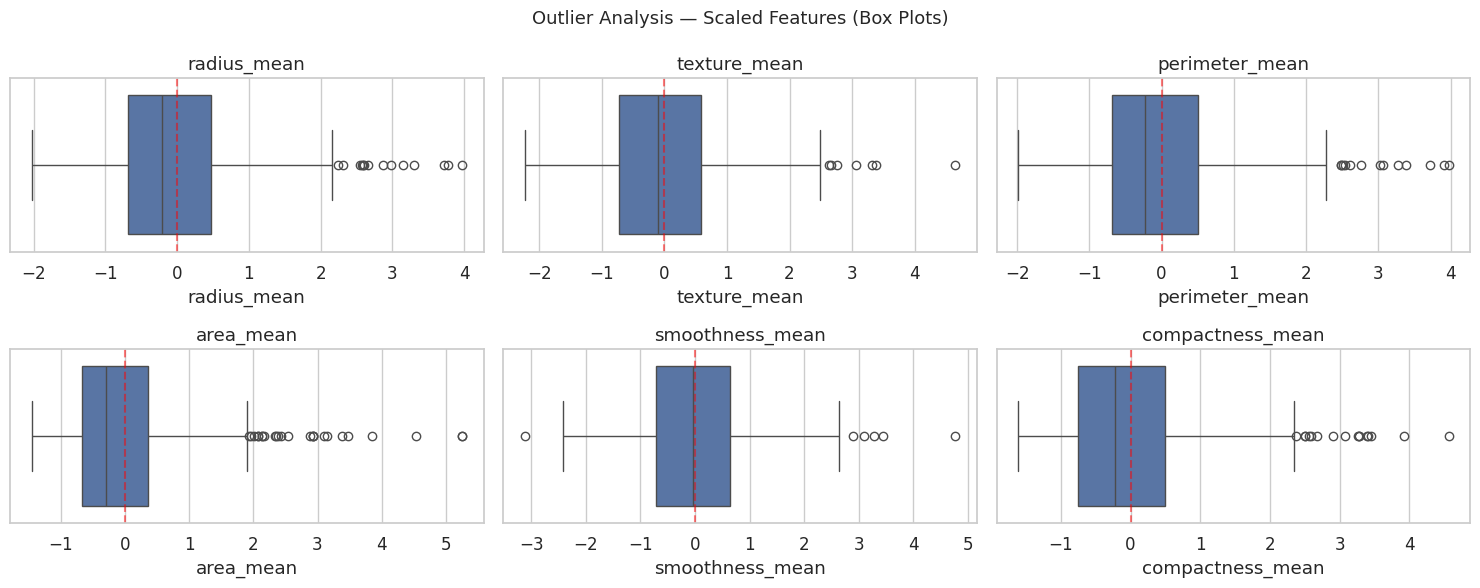

In [15]:
cols_to_plot = [
    'radius_mean',
    'texture_mean',
    'perimeter_mean',
    'area_mean',
    'smoothness_mean',
    'compactness_mean'
]

plt.figure(figsize=(15, 6))
for i, col in enumerate(cols_to_plot):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(x=X_scaled_df[col])
    plt.title(col)
    plt.axvline(0, color='red', linestyle='--', alpha=0.5)
plt.suptitle("Outlier Analysis — Scaled Features (Box Plots)", fontsize=13)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/outlier_boxplots.png", dpi=150, bbox_inches='tight')
plt.show()



In [16]:
# IQR-based outlier counting per feature

iqr_outlier_counts = []

for col in df.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    iqr_outlier_counts.append([col, outliers])

iqr_outlier_df = pd.DataFrame(iqr_outlier_counts, columns=["Feature", "IQR Outliers"])
iqr_outlier_df = iqr_outlier_df.sort_values(by="IQR Outliers", ascending=False)

print(iqr_outlier_df)

                    Feature  IQR Outliers
13                  area_se            65
10                radius_se            38
12             perimeter_se            38
23               area_worst            35
14            smoothness_se            30
19     fractal_dimension_se            28
15           compactness_se            28
18              symmetry_se            27
3                 area_mean            25
29  fractal_dimension_worst            24
28           symmetry_worst            23
16             concavity_se            22
11               texture_se            20
17        concave points_se            19
6            concavity_mean            18
20             radius_worst            17
25        compactness_worst            16
5          compactness_mean            16
8             symmetry_mean            15
9    fractal_dimension_mean            15
22          perimeter_worst            15
0               radius_mean            14
2            perimeter_mean       

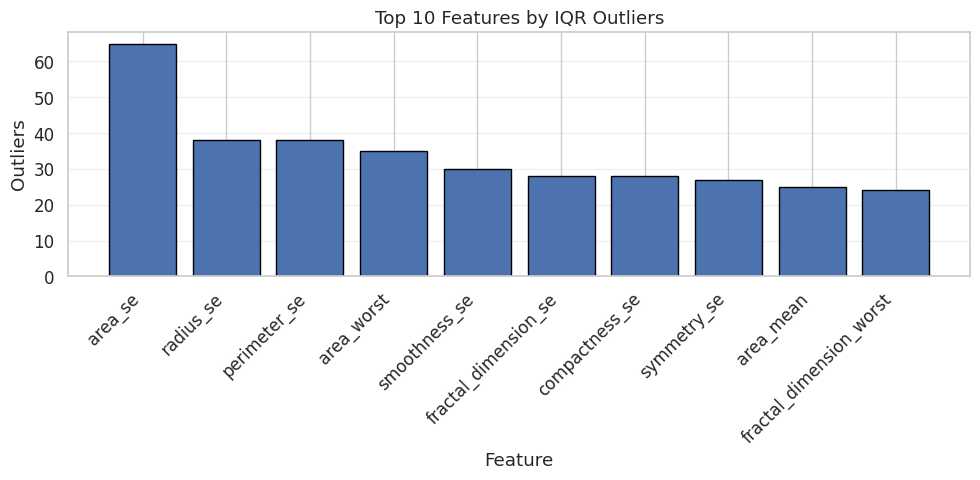

In [17]:
top10 = iqr_outlier_df.sort_values("IQR Outliers", ascending=False).head(10)

plt.figure(figsize=(10,5))

plt.bar(
    top10["Feature"],
    top10["IQR Outliers"],
    edgecolor="black"
)

plt.xticks(rotation=45, ha="right")
plt.title("Top 10 Features by IQR Outliers")
plt.xlabel("Feature")
plt.ylabel("Outliers")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

- 2.5. Handling Outliers (Winsorisation)

Extreme values are capped using IQR-based bounds (1.5 × IQR rule)
This reduces the influence of outliers without removing data, which is important because PCA is sensitive to extreme values.

In [18]:
print("\n" + "="*70)
print("SECTION 2.5: IQR OUTLIER HANDLING (CAPPING METHOD)")
print("="*70)

before = df.copy()

summary_before = before.describe(percentiles=[0.25, 0.75]).T[['min', '25%', '75%', 'max']]
print("Before IQR capping (first 10 features):")
print(summary_before.head(10).round(4))


SECTION 2.5: IQR OUTLIER HANDLING (CAPPING METHOD)
Before IQR capping (first 10 features):
                             min       25%       75%        max
radius_mean               6.9810   11.7000   15.7800    28.1100
texture_mean              9.7100   16.1700   21.8000    39.2800
perimeter_mean           43.7900   75.1700  104.1000   188.5000
area_mean               143.5000  420.3000  782.7000  2501.0000
smoothness_mean           0.0526    0.0864    0.1053     0.1634
compactness_mean          0.0194    0.0649    0.1304     0.3454
concavity_mean            0.0000    0.0296    0.1307     0.4268
concave points_mean       0.0000    0.0203    0.0740     0.2012
symmetry_mean             0.1060    0.1619    0.1957     0.3040
fractal_dimension_mean    0.0500    0.0577    0.0661     0.0974


In [19]:
#do clipping
# IQR capping
for col in df.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lo = Q1 - 1.5 * IQR
    hi = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lo, hi)

In [20]:
#After clipping
summary_after = df.describe(percentiles=[0.25, 0.75]).T[['min', '25%', '75%', 'max']]
print("\nAfter IQR capping (first 10 features):")
print(summary_after.head(10).round(4))

print("\nAfter IQR capping (last 10 features):")
print(summary_after.tail(10).round(4))


After IQR capping (first 10 features):
                             min       25%       75%        max
radius_mean               6.9810   11.7000   15.7800    21.9000
texture_mean              9.7100   16.1700   21.8000    30.2450
perimeter_mean           43.7900   75.1700  104.1000   147.4950
area_mean               143.5000  420.3000  782.7000  1326.3000
smoothness_mean           0.0580    0.0864    0.1053     0.1337
compactness_mean          0.0194    0.0649    0.1304     0.2286
concavity_mean            0.0000    0.0296    0.1307     0.2824
concave points_mean       0.0000    0.0203    0.0740     0.1545
symmetry_mean             0.1112    0.1619    0.1957     0.2464
fractal_dimension_mean    0.0500    0.0577    0.0661     0.0787

After IQR capping (last 10 features):
                              min       25%        75%        max
radius_worst               7.9300   13.0100    18.7900    27.4600
texture_worst             12.0200   21.0800    29.7200    42.6800
perimeter_worst    

In [21]:
changes = {}

for col in df.columns:
    Q1 = before[col].quantile(0.25)
    Q3 = before[col].quantile(0.75)
    IQR = Q3 - Q1

    lo = Q1 - 1.5 * IQR
    hi = Q3 + 1.5 * IQR

    changed = ((before[col] < lo) | (before[col] > hi)).sum()
    changes[col] = changed

In [22]:
changes_series = pd.Series(changes).sort_values(ascending=False)
print("\nValues changed by winsorisation per feature:")
print(changes_series)


Values changed by winsorisation per feature:
area_se                    65
radius_se                  38
perimeter_se               38
area_worst                 35
smoothness_se              30
fractal_dimension_se       28
compactness_se             28
symmetry_se                27
area_mean                  25
fractal_dimension_worst    24
symmetry_worst             23
concavity_se               22
texture_se                 20
concave points_se          19
concavity_mean             18
radius_worst               17
compactness_worst          16
compactness_mean           16
symmetry_mean              15
fractal_dimension_mean     15
perimeter_worst            15
radius_mean                14
perimeter_mean             13
concavity_worst            12
concave points_mean        10
texture_mean                7
smoothness_worst            7
smoothness_mean             6
texture_worst               5
concave points_worst        0
dtype: int64


In [23]:
df.columns

Index(['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

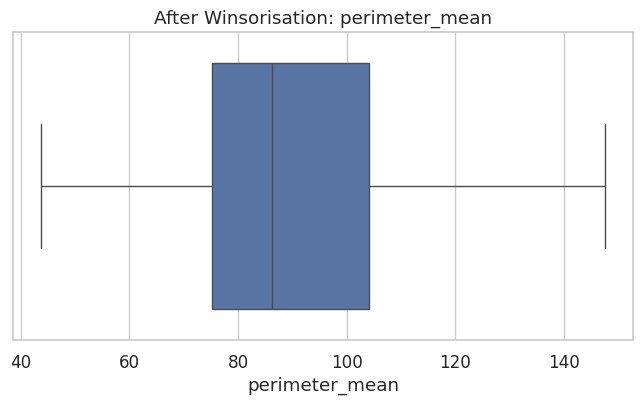

In [24]:
# Post-clipping box plot for one feature

col_check = df.columns[2]
plt.figure(figsize=(8, 4))
sns.boxplot(x=df[col_check])
plt.title(f"After Winsorisation: {col_check}")
plt.savefig(f"{OUT_DIR}/post_winsorise_boxplot.png", dpi=150, bbox_inches='tight')
plt.show()

- 2.6 Final Data Checks

In [25]:
print("\n" + "="*70)
print("SECTION 2.6: FINAL DATA VERIFICATION")
print("="*70)

# 1. Check missing values
missing_total = df.isnull().sum().sum()
print(f"Total missing values after preprocessing: {missing_total}")

# 2. Check infinite values
inf_check = np.isinf(df.select_dtypes(include=[np.number])).sum().sum()
print(f"Total infinite values: {inf_check}")

# 3. Check constant / near-zero variance features
constant_cols = [col for col in df.columns if df[col].nunique() <= 1]
print(f"Constant columns: {constant_cols if constant_cols else 'None'}")

# 4. Confirm dataset shape
print(f"Final dataset shape for PCA input: {df.shape}")

# 5. Create final feature matrix for PCA pipeline
X_final = df.copy()



SECTION 2.6: FINAL DATA VERIFICATION
Total missing values after preprocessing: 0
Total infinite values: 0
Constant columns: None
Final dataset shape for PCA input: (569, 30)


- 2.7.1.  Variance Analysis on Scaled Features

In [26]:
X_final = df.copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_final)
X_scaled_df = pd.DataFrame(X_scaled, columns=X_final.columns)

In [27]:
variance_df = pd.DataFrame({
    "Feature": X_scaled_df.columns,
    "Variance": X_scaled_df.var().values
}).sort_values(by="Variance", ascending=False)
print("Variance on scaled dataset")
print(round(variance_df))

Variance on scaled dataset
                    Feature  Variance
12             perimeter_se       1.0
25        compactness_worst       1.0
19     fractal_dimension_se       1.0
23               area_worst       1.0
2            perimeter_mean       1.0
10                radius_se       1.0
28           symmetry_worst       1.0
17        concave points_se       1.0
15           compactness_se       1.0
21            texture_worst       1.0
7       concave points_mean       1.0
4           smoothness_mean       1.0
1              texture_mean       1.0
0               radius_mean       1.0
24         smoothness_worst       1.0
16             concavity_se       1.0
5          compactness_mean       1.0
26          concavity_worst       1.0
8             symmetry_mean       1.0
11               texture_se       1.0
18              symmetry_se       1.0
9    fractal_dimension_mean       1.0
27     concave points_worst       1.0
20             radius_worst       1.0
13                  are

Variance analysis on the scaled features confirms that all variables have been successfully standardized to unit variance, ensuring that features with larger original scales do not disproportionately influence the Principal Component Analysis.

- 2.7.2 Variance Analysis on Unscaled Features


In [28]:
raw_variance = df.var().sort_values(ascending=False)
variance_raw_df = pd.DataFrame({
    "Feature": raw_variance.index,
    "Raw Variance": raw_variance.values
})

print("\n" + "="*70)
print("SECTION 2.7: RAW VARIANCE ANALYSIS (POST-WINSORISATION)")
print("="*70)
print(variance_raw_df.head(10).to_string(index=False))



SECTION 2.7: RAW VARIANCE ANALYSIS (POST-WINSORISATION)
        Feature  Raw Variance
     area_worst 226238.394318
      area_mean  93234.657977
perimeter_worst   1021.299516
        area_se    590.223447
 perimeter_mean    531.174238
  texture_worst     36.655826
   radius_worst     21.042850
   texture_mean     17.535244
    radius_mean     11.155764
   perimeter_se      1.968359


- 2.8 Correlation Matrix

Here i am checking suitability of PCA: correlation strength

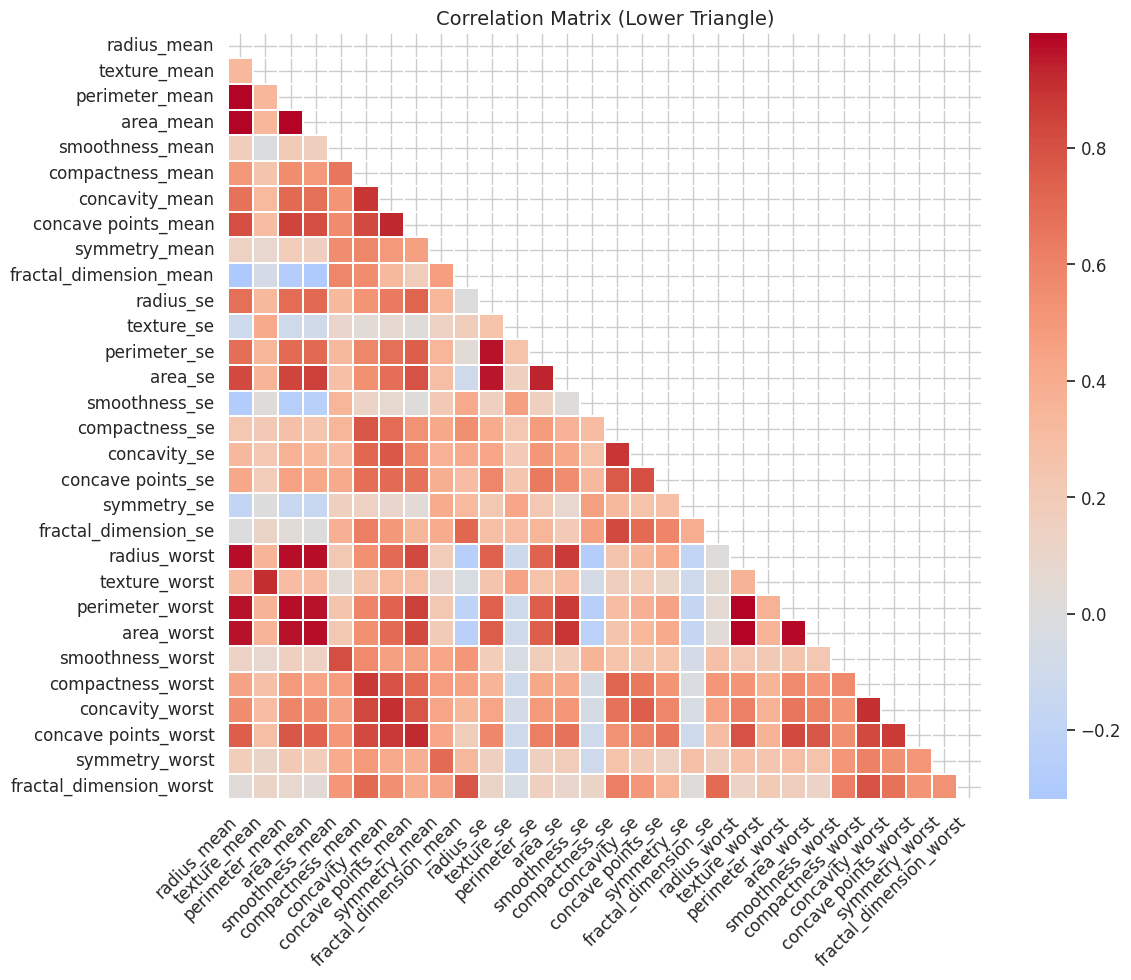

In [29]:
corr = X_scaled_df.corr()

# Mask for upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(12, 10))

sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    center=0,
    annot=False,       # no numbers
    linewidths=0.3,
    cbar=True
)

plt.title("Correlation Matrix (Lower Triangle)", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Comments:

We have many correlated variables as we can see from heatmap. Hence PCA is a very good choice.

- 2.9 Strong Correlations (Top pairs)

In [30]:
corr = X_scaled_df.corr()

# Taking upper triangle only and removing duplicates
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

strong_corr = (
    upper.unstack()
    .dropna()
    .sort_values(ascending=False)
)

strong_corr.head(40)

perimeter_mean        radius_mean            0.997692
area_mean             radius_mean            0.993891
perimeter_worst       radius_worst           0.993663
area_worst            radius_worst           0.993198
area_mean             perimeter_mean         0.991861
area_worst            perimeter_worst        0.986301
radius_worst          perimeter_mean         0.974555
perimeter_worst       perimeter_mean         0.973889
radius_worst          area_mean              0.973784
                      radius_mean            0.973472
area_worst            area_mean              0.973460
perimeter_worst       radius_mean            0.967506
                      area_mean              0.967206
perimeter_se          radius_se              0.967202
area_worst            perimeter_mean         0.963900
                      radius_mean            0.962549
area_se               radius_se              0.957346
                      perimeter_se           0.934078
concave points_mean   concavity_mean         0.928382
concave points_worst  concave points_mean    0.916542
texture_worst         texture_mean           0.911642
concavity_worst       compactness_worst      0.906424
                      concavity_mean         0.904529
area_worst            area_se                0.891669
concavity_mean        compactness_mean       0.889882
concavity_se          compactness_se         0.886897
compactness_worst     compactness_mean       0.883162
concave points_worst  concavity_mean         0.881502
                      concavity_worst        0.875307
radius_worst          area_se                0.873692
perimeter_worst       area_se                0.869239
area_se               area_mean              0.857245
perimeter_worst       concave points_mean    0.855906
concave points_mean   perimeter_mean         0.841871
area_se               perimeter_mean         0.840760
concavity_worst       compactness_mean       0.835009
area_se               radius_mean            0.832692
concave points_mean   compactness_mean       0.832541
radius_worst          concave points_mean    0.832188
area_worst            concave points_mean    0.830127
dtype: float64

High correlation indicates redundancy in the feature space, meaning PCA is appropriate to extract orthogonal latent structures such as “concave points_mean”, “perimeter_mean”, or “area_worst”.

- 2.10 Skewness Check

In [31]:
skewness = X_scaled_df.skew().sort_values(ascending=False)

skewness.head(10)

,0
area_se,1.130940
area_worst,1.048970
perimeter_se,1.034389
radius_se,1.025031
concavity_mean,1.023859
concave points_mean,1.004049
compactness_se,0.990285
fractal_dimension_se,0.979344
area_mean,0.922884
concavity_se,0.916740


**Section 3: PCA Implementation**

- 3.1. Covariance Matrix

In [32]:
# Step 1: Replace inf with NaN
X_clean = X_scaled_df.replace([np.inf, -np.inf], np.nan)

# Step 2: Drop problematic rows
X_clean = X_clean.dropna()

# Step 3: Remove zero variance columns
X_clean = X_clean.loc[:, X_clean.std() > 0]

# Step 4: Covariance matrix
cov_matrix = np.cov(X_clean, rowvar=False)

# Step 5: Convert to DataFrame
cov_df = pd.DataFrame(cov_matrix,
                      index=X_clean.columns,
                      columns=X_clean.columns)

print("Covariance Matrix Shape:", cov_df.shape)


display(cov_df.iloc[:10, :10].round(2))

Covariance Matrix Shape: (30, 30)


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean
radius_mean,1.00,0.33,1.00,1.00,0.17,0.50,0.68,0.81,0.15,-0.32
texture_mean,0.33,1.00,0.34,0.34,-0.02,0.24,0.32,0.30,0.08,-0.07
perimeter_mean,1.00,0.34,1.00,0.99,0.21,0.55,0.72,0.84,0.18,-0.27
area_mean,1.00,0.34,0.99,1.00,0.17,0.50,0.68,0.82,0.16,-0.30
smoothness_mean,0.17,-0.02,0.21,0.17,1.00,0.66,0.53,0.56,0.56,0.59
compactness_mean,0.50,0.24,0.55,0.50,0.66,1.00,0.89,0.83,0.59,0.56
concavity_mean,0.68,0.32,0.72,0.68,0.53,0.89,1.00,0.93,0.49,0.33
concave points_mean,0.81,0.30,0.84,0.82,0.56,0.83,0.93,1.00,0.46,0.17
symmetry_mean,0.15,0.08,0.18,0.16,0.56,0.59,0.49,0.46,1.00,0.47
fractal_dimension_mean,-0.32,-0.07,-0.27,-0.30,0.59,0.56,0.33,0.17,0.47,1.00


- 3.2. Eigen Values and Eigen vectors

In [33]:

# Applying PCA (keep 80% variance)

pca = PCA(n_components=0.80, random_state=42)
X_pca = pca.fit_transform(X_scaled_df)

# Extracting PCA outputs
eig_values = pca.explained_variance_
eig_vectors = pca.components_.T  # important: transpose for loading format

explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

# Converting to DataFrame
n_components = X_pca.shape[1]

pca_df = pd.DataFrame(
    X_pca,
    columns=[f"PC{i+1}" for i in range(n_components)]
)

# Variance Summary Table
eig_df = pd.DataFrame({
    "Eigenvalue": eig_values,
    "Explained Variance (%)": explained_variance_ratio * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})

print("="*60)
print("PCA SUMMARY")
print("="*60)
display(eig_df.round(4))

print("\nFinal PCA shape:", pca_df.shape)
print("Components retained:", n_components)

PCA SUMMARY


,Eigenvalue,Explained Variance (%),Cumulative Variance (%)
0,14.0846,46.8662,46.8662
1,5.6365,18.7554,65.6216
2,2.7527,9.1595,74.7811
3,1.9043,6.3365,81.1176



Final PCA shape: (569, 4)
Components retained: 4


**Interpretation:**

The variance in this dataset is quite clearly concentrated in the first few principal components rather than being spread evenly across all of them. PC1 alone explains about 46.9% of the total variance, followed by PC2 at 18.7% and PC3 at 9.2%, which shows that a relatively small number of underlying patterns are driving most of the structure in the data. This suggests the dataset is not random or weakly structured, but instead has strong relationships between variables that PCA is able to capture effectively.

By the time we reach the fourth principal component, we already retain just over 81% of the total variance, meaning most of the important information in the dataset can be represented using only four components instead of the full feature set. After this point, each additional component adds only a small amount of information (generally under 6%), which shows clear diminishing returns. In other words, later components are mostly capturing fine detail or noise rather than anything fundamentally new.

Overall, PCA works well here because it compresses a large, complex dataset into a much smaller number of meaningful components while still keeping most of the important information intact.


- 3.3 Scree Plot

By looking at this plot, we will decide how much components we need to include to capture enough variability

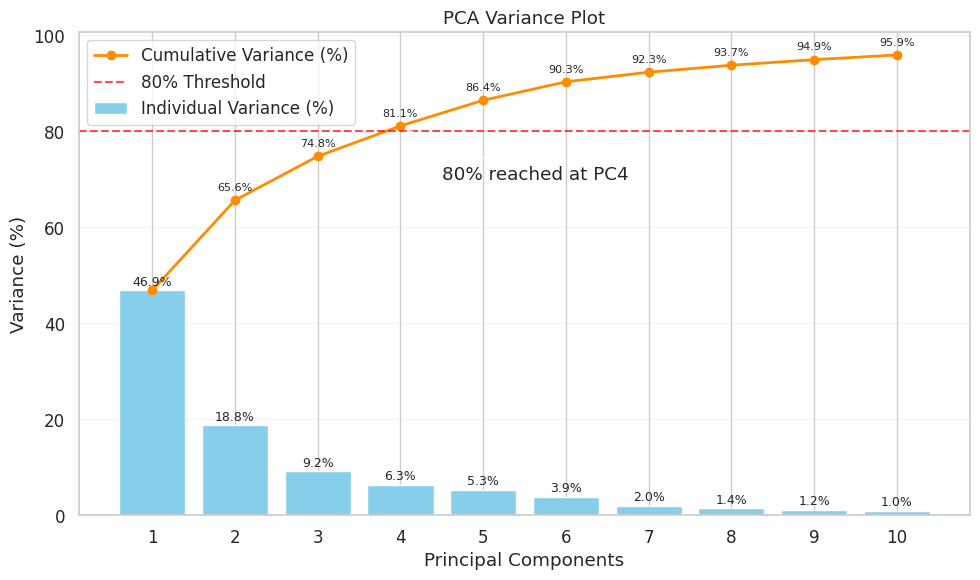

In [34]:
n_view = 10

pca_simple = PCA(n_components=n_view)
pca_simple.fit(X_scaled_df)

exp_var = pca_simple.explained_variance_ratio_ * 100
cum_var = np.cumsum(exp_var)

x = np.arange(1, n_view + 1)

target_var = 80
pc_needed = np.argmax(cum_var >= target_var) + 1

plt.figure(figsize=(10,6))

# Bars: individual variance
bars = plt.bar(
    x,
    exp_var,
    color='skyblue',
    label='Individual Variance (%)'
)

# ADD INDIVIDUAL % LABELS ON BARS
for i, v in enumerate(exp_var):
    plt.text(
        x[i],
        v + 1,                 # slightly above bar
        f'{v:.1f}%',
        ha='center',
        fontsize=9
    )

# Cumulative variance line
plt.plot(
    x,
    cum_var,
    marker='o',
    color='darkorange',
    linewidth=2,
    label='Cumulative Variance (%)'
)

# Optional labels on cumulative points too
# Labels on cumulative line (skip first point)
for i, v in enumerate(cum_var[1:], start=1):
    plt.text(
        x[i],
        v + 2,
        f'{v:.1f}%',
        ha='center',
        fontsize=8
    )


# 80% threshold
plt.axhline(
    y=target_var,
    color='red',
    linestyle='--',
    alpha=0.7,
    label='80% Threshold'
)

plt.annotate(
    f'80% reached at PC{pc_needed}',
    xy=(pc_needed, target_var),
    xytext=(pc_needed+0.5, target_var-10),
    arrowprops=dict(arrowstyle='->')
)

plt.title("PCA Variance Plot")
plt.xlabel("Principal Components")
plt.ylabel("Variance (%)")
plt.xticks(x)
plt.grid(axis='y', alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:**
The Scree Plot demonstrates that the first four principal components (PCs) are sufficient to capture approximately 81.2% of the total variance in the Breast Cancer dataset. The first component (PC1) is exceptionally dominant, accounting for nearly 47% of the variability, which indicates that a single latent factor—likely related to the overall size and shape of cell nuclei—captures almost half of the diagnostic information. The sharp "elbow" observed after PC2 and PC3, followed by the crossing of the 80% threshold at PC4, justifies a significant reduction in dimensionality from 30 variables to just 4 while preserving the most meaningful structural patterns.

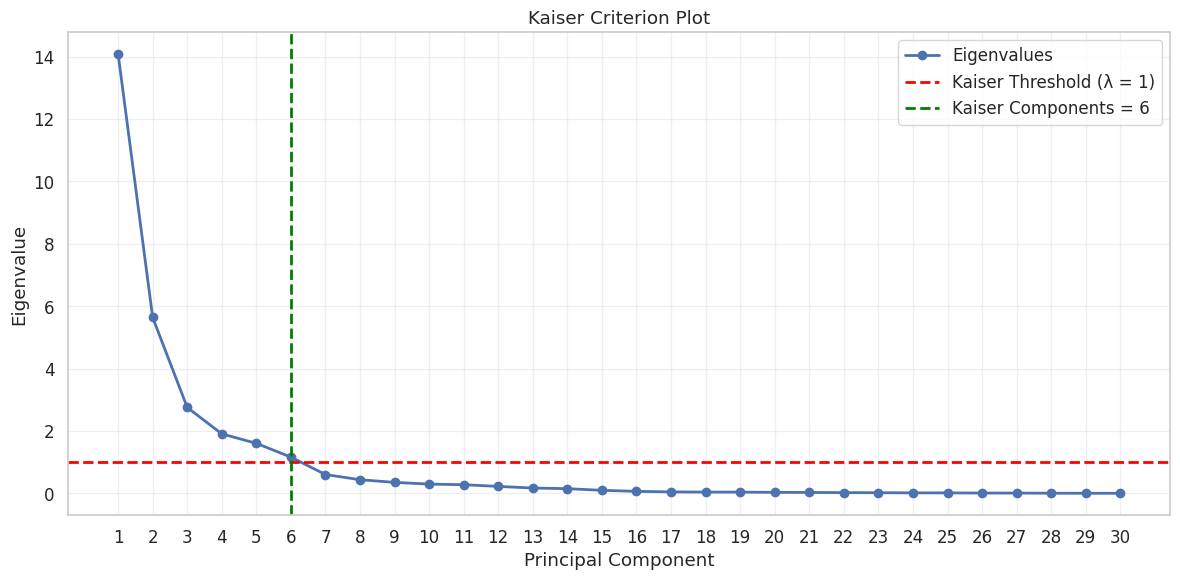

Kaiser retained components: 6


In [35]:
pca_full = PCA()
pca_full.fit(X_scaled_df)

# Get all eigenvalues
eig_values = pca_full.explained_variance_

x = np.arange(1, len(eig_values) + 1)

plt.figure(figsize=(12,6))

# Kaiser plot
plt.plot(
    x,
    eig_values,
    marker='o',
    linewidth=2,
    label='Eigenvalues'
)

# Kaiser threshold
plt.axhline(
    y=1,
    color='red',
    linestyle='--',
    linewidth=2,
    label='Kaiser Threshold (λ = 1)'
)

# Components with eigenvalue >1
kaiser_components = np.sum(eig_values > 1)

plt.axvline(
    x=kaiser_components,
    color='green',
    linestyle='--',
    linewidth=2,
    label=f'Kaiser Components = {kaiser_components}'
)

plt.xlabel("Principal Component")
plt.ylabel("Eigenvalue")
plt.title("Kaiser Criterion Plot")
plt.xticks(x)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("Kaiser retained components:", kaiser_components)

**Interpretation:**
The Kaiser Criterion is more conservative, suggesting 6 components should be kept because their eigenvalues are greater than 1. This means these six factors each carry more "weight" than any single original variable. While the 80% rule offers a simpler model, following the Kaiser Criterion ensures you don't lose subtler but potentially important diagnostic details, like texture or symmetry, which are vital for distinguishing malignant tumors.

- 3.4 Derive the Eigenvectors / Loadings

In [36]:
loadings = pd.DataFrame(
    eig_vectors[:, :n_components],
    columns=[f"PC{i+1}" for i in range(n_components)],
    index=X_clean.columns   # or X_scaled_df.columns
)

print("="*60)
print("LOADINGS (EIGENVECTORS)")
print("="*60)
print(loadings.head(10).round(4))

LOADINGS (EIGENVECTORS)
                           PC1     PC2     PC3     PC4
radius_mean             0.2121 -0.2401 -0.0103 -0.0530
texture_mean            0.1053 -0.0590  0.1769  0.5813
perimeter_mean          0.2207 -0.2204 -0.0125 -0.0527
area_mean               0.2138 -0.2364  0.0098 -0.0541
smoothness_mean         0.1390  0.1957 -0.1072 -0.1052
compactness_mean        0.2338  0.1535 -0.0808 -0.0260
concavity_mean          0.2506  0.0553 -0.0210 -0.0204
concave points_mean     0.2539 -0.0315 -0.0216 -0.0721
symmetry_mean           0.1336  0.1897 -0.0357 -0.0421
fractal_dimension_mean  0.0604  0.3706 -0.0567 -0.0128


In [37]:
print(eig_vectors[:, :n_components].shape)
print(len(X_clean.columns))

(30, 4)
30


- 3.5 Transformation of data into principal component space

In [38]:
# Transform data into principal component space
X_pca = pca.transform(X_scaled_df)

pca_df = pd.DataFrame(
    X_pca,
    columns=[f"PC{i+1}" for i in range(n_components)]
)

print("="*60)
print("PCA TRANSFORMED DATA (Principal Component Scores)")
print("="*60)
print(pca_df.head().round(4))

print("\nFinal PCA Shape:", pca_df.shape)

PCA TRANSFORMED DATA (Principal Component Scores)
      PC1     PC2     PC3     PC4
0  9.2678  2.2791 -1.7506 -3.3031
1  2.9053 -4.2989 -0.5195 -1.2812
2  6.6598 -1.2950 -0.2251 -1.1643
3  5.6653  7.3448 -1.4583  0.0290
4  4.8483 -2.0555  1.5432 -3.6025

Final PCA Shape: (569, 4)


In [39]:
print("="*60)
print("TOTAL VARIANCE EXPLAINED")
print("="*60)
print(np.sum(explained_variance_ratio[:n_components]))

TOTAL VARIANCE EXPLAINED
0.8111760183778536


- 3.6 Interpretation of  Principal Components

In [40]:
for pc in ['PC1','PC2','PC3']:
    print(f"\nTop loadings for {pc}")
    print(loadings[pc].abs().sort_values(ascending=False).head(8))


Top loadings for PC1
concave points_mean     0.253877
concavity_mean          0.250630
concave points_worst    0.246916
compactness_mean        0.233830
perimeter_worst         0.231171
concavity_worst         0.228839
area_worst              0.223540
radius_worst            0.223293
Name: PC1, dtype: float64

Top loadings for PC2
fractal_dimension_mean     0.370642
fractal_dimension_se       0.292755
fractal_dimension_worst    0.271048
radius_mean                0.240136
area_mean                  0.236390
smoothness_se              0.235404
compactness_se             0.223820
radius_worst               0.221555
Name: PC2, dtype: float64

Top loadings for PC3
texture_se                 0.448452
symmetry_se                0.324241
smoothness_se              0.309827
symmetry_worst             0.261883
radius_se                  0.258542
perimeter_se               0.254822
smoothness_worst           0.236213
fractal_dimension_worst    0.231114
Name: PC3, dtype: float64


**Comments on output:**


The principal component loadings indicate the variables that contribute most strongly to each component and help identify the underlying latent factors represented by the PCA.

**PC1 (Morphological and Tumour Aggressiveness Features):**
PC1 is primarily driven by features related to tumour shape irregularity and size, including concave points_mean, concavity_mean, concave points_worst, compactness_mean, and size-related measures such as perimeter_worst, area_worst, and radius_worst. This suggests that PC1 represents a general malignancy or tumour severity dimension, where higher values are associated with more irregular, larger, and more aggressive tumour characteristics.

**PC2 (Nuclear Texture and Boundary Irregularity):**
PC2 is dominated by fractal dimension measures (fractal_dimension_mean, fractal_dimension_se, fractal_dimension_worst) along with size-related features such as radius_mean and area_mean, and variability measures like smoothness_se and compactness_se. This component appears to capture boundary complexity and textural irregularity of cell nuclei, reflecting structural complexity and variation in tumour morphology.

**PC3 (Cell Texture and Shape Variability):**
PC3 is mainly influenced by texture and shape variability features, including texture_se, symmetry_se, smoothness_se, radius_se, and perimeter_se, along with symmetry_worst and fractal_dimension_worst. This suggests that PC3 represents local structural variability and cell shape heterogeneity, particularly variability in nuclear texture and symmetry across samples.

- 3.7 Heatmaps of loading for first 5 Principle Component

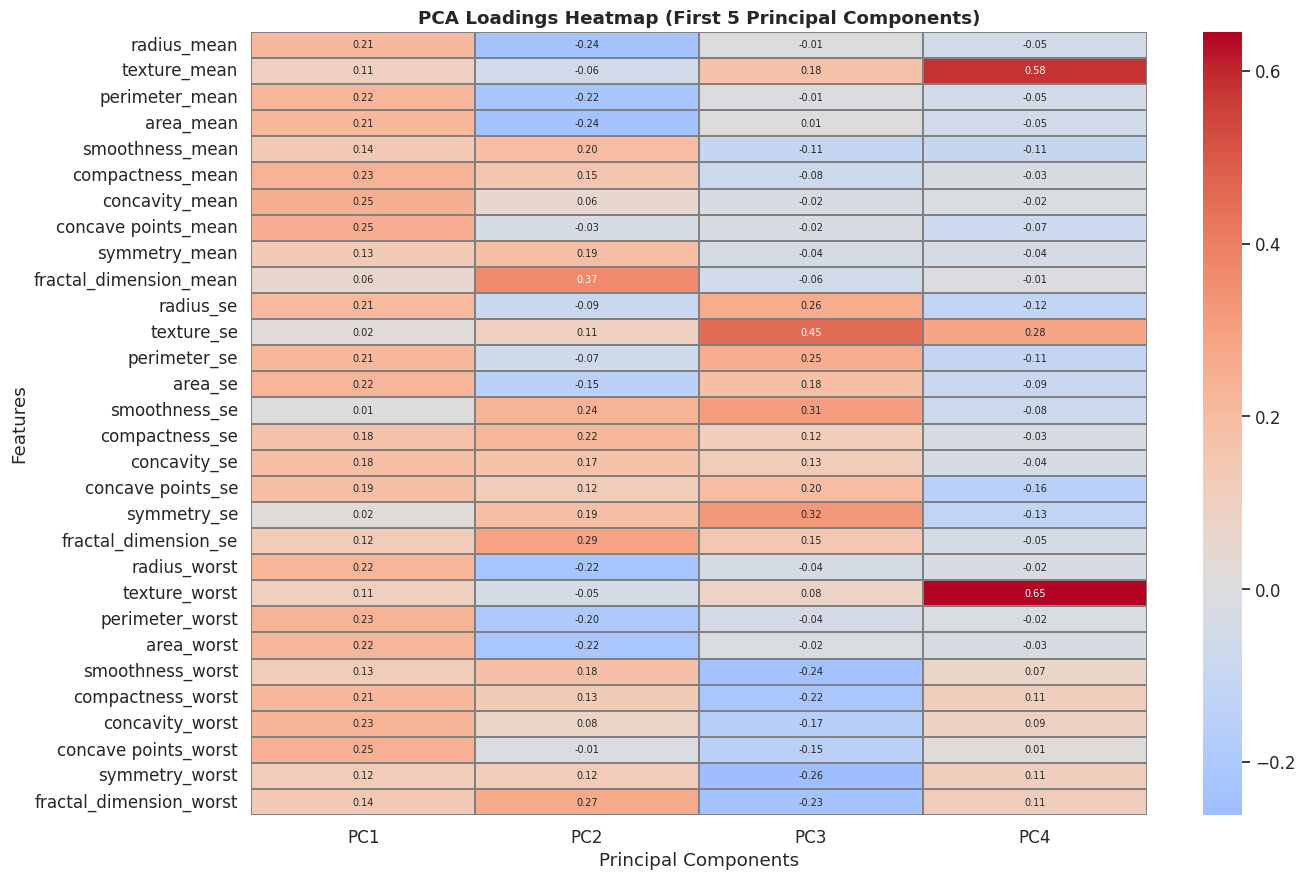

In [41]:
plt.figure(figsize=(14, 9))

sns.heatmap(
    loadings.iloc[:, :5],
    cmap='coolwarm',
    center=0,
    linewidths=0.3,
    linecolor='gray',
    annot=True,          # show values
    fmt=".2f",           # 2 decimal places
    annot_kws={"size": 7},
    cbar=True
)

plt.title("PCA Loadings Heatmap (First 5 Principal Components)", fontweight='bold')
plt.xlabel("Principal Components")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

- 3.8 PCA Score Plot (PC1 vs PC2)

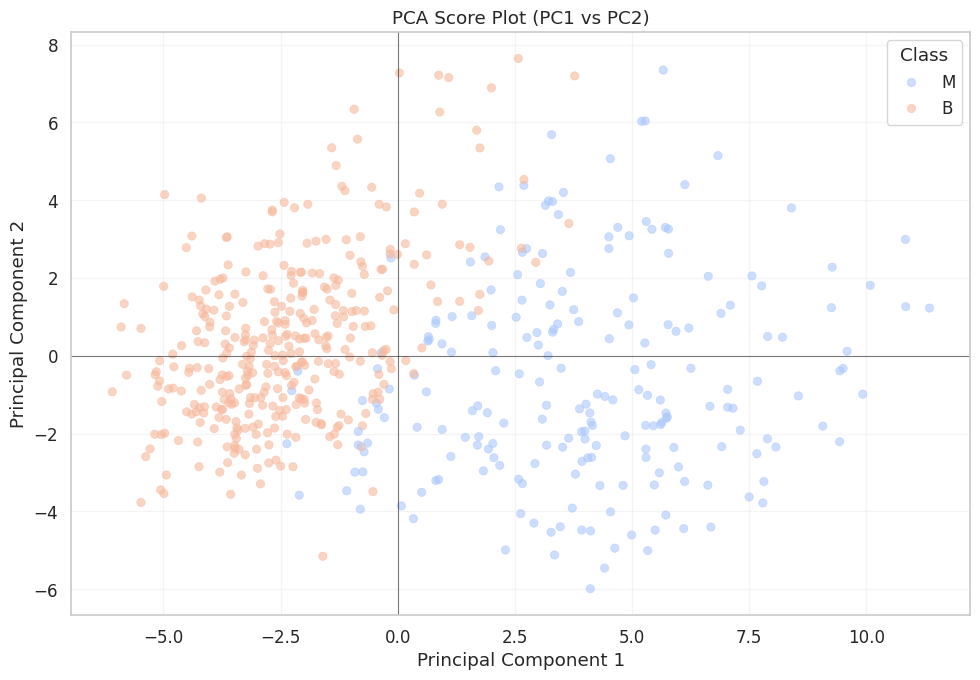

In [42]:
plt.figure(figsize=(10, 7))

# Scatter with class colouring
sns.scatterplot(
    x=pca_df["PC1"],
    y=pca_df["PC2"],
    hue=y,                 # class labels (benign/malignant)
    alpha=0.6,
    palette="coolwarm",
    edgecolor=None
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Score Plot (PC1 vs PC2)")
plt.axhline(0, color='black', linewidth=0.8, alpha=0.5)
plt.axvline(0, color='black', linewidth=0.8, alpha=0.5)

plt.legend(title="Class", loc="best")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Note:
Through this code, **B** and **M** refer to the two diagnostic classes: **Benign** (non-cancerous) and **Malignant** (cancerous) tumors.

**Interpretation:**

The PCA score plot reveals that the high-dimensional data can be effectively simplified into two dimensions while maintaining clear **class separation**. Most of the diagnostic difference is captured along **PC1**, with Malignant samples (blue) and Benign samples (orange) forming distinct clusters on opposite sides of the vertical axis. While some overlap exists in the center, the overall layout proves that the most significant variations in the dataset align closely with the actual tumor diagnosis.

- 3.9 Biplot

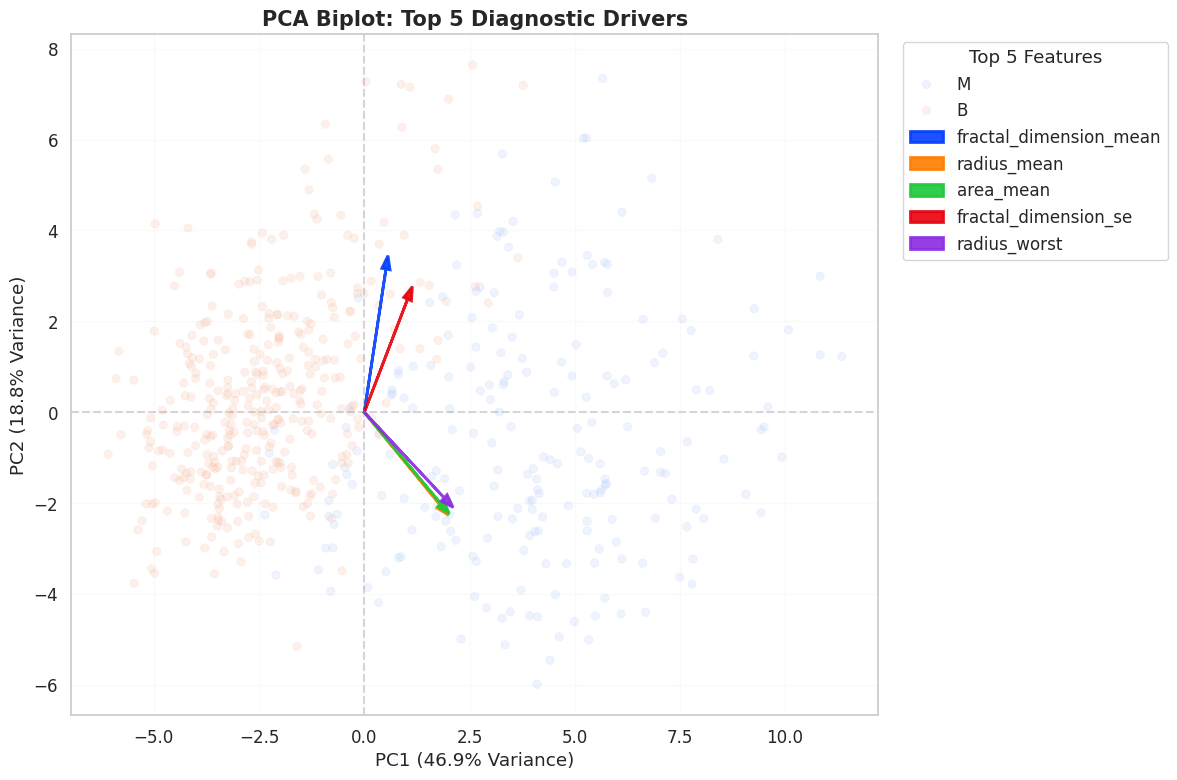

In [43]:
# BIPLOT: TOP 5 DISTINCT VECTORS

def plot_top5_biplot(score, coeff, labels, targets):
    plt.figure(figsize=(12, 8))

    # 1. Plot the patients (Scores)
    # Using low alpha to make the vectors pop
    sns.scatterplot(x=score[:,0], y=score[:,1], hue=targets,
                    palette='coolwarm', alpha=0.2, edgecolor=None)

    # 2. Get Top 5 indices based on magnitude
    magnitudes = np.sqrt(coeff[:,0]**2 + coeff[:,1]**2)
    top_5_indices = np.argsort(magnitudes)[-5:][::-1]
    colors = sns.color_palette("bright", 5)

    # 3. Plot the 5 distinct vectors
    for idx, color in zip(top_5_indices, colors):
        vx, vy = coeff[idx,0]*8.5, coeff[idx,1]*8.5

        plt.arrow(0, 0, vx, vy, color=color, alpha=0.9,
                  head_width=0.2, linewidth=2, label=labels[idx])

    # 4. Formatting
    plt.xlabel(f"PC1 ({eig_df.iloc[0,1]:.1f}% Variance)")
    plt.ylabel(f"PC2 ({eig_df.iloc[1,1]:.1f}% Variance)")
    plt.title("PCA Biplot: Top 5 Diagnostic Drivers", fontsize=15, fontweight='bold')

    # Position legend to avoid obscuring data
    plt.legend(title="Top 5 Features", bbox_to_anchor=(1.02, 1), loc='upper left')

    plt.axhline(0, color='gray', linestyle='--', alpha=0.3)
    plt.axvline(0, color='gray', linestyle='--', alpha=0.3)
    plt.grid(alpha=0.1)
    plt.tight_layout()
    plt.show()

# Execute for the cleanest possible visual
plot_top5_biplot(X_pca[:, 0:2], eig_vectors[:, 0:2],
                 labels=X_clean.columns, targets=y)

Interpretation:
The PCA biplot illustrates which features exert the most influence on the separation of tumor classes. The **vectors** for size-related features like **radius_mean**, **area_mean**, and **radius_worst** point strongly toward the Malignant (M) cluster, confirming that larger dimensions are primary drivers of a malignant diagnosis. Meanwhile, the vectors for **fractal_dimension** variants follow a different trajectory along PC2, showing that while they contribute to the data's overall variance, they are less directly tied to class separation than the size metrics. This visualization confirms that the model relies on a combination of physical scale and structural complexity to differentiate between the two groups.

- 3.10 Kaiser Criterion

In [44]:
kaiser_components = sum(eig_values > 1)
print("Components retained by Kaiser criterion:", kaiser_components)

Components retained by Kaiser criterion: 6


- 3.11  LATENT DISEASE TRAJECTORY

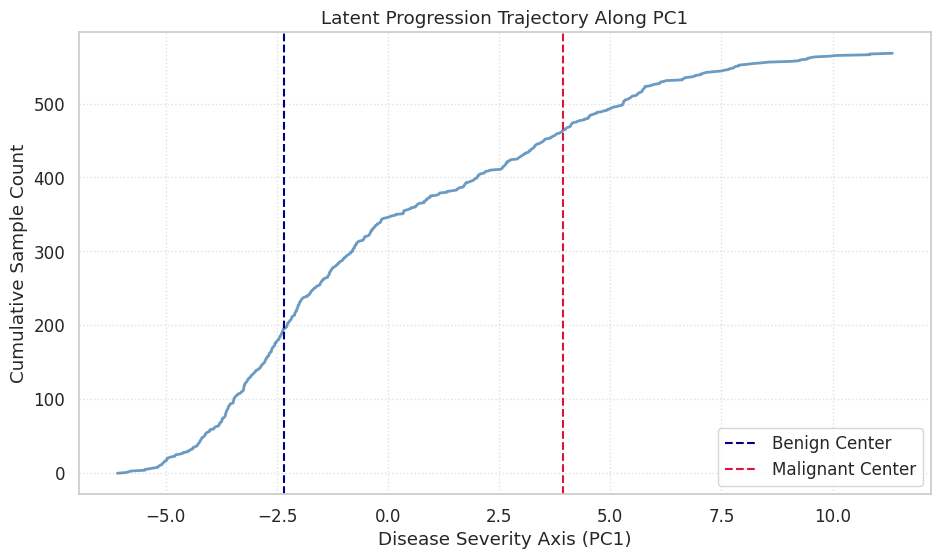

In [45]:
trajectory = pd.DataFrame({
    "PC1": X_pca[:, 0], # Using your manual PC1
    "Diagnosis": y.values
})

# Sort by PC1 to create the cumulative progression curve
trajectory = trajectory.sort_values("PC1")

plt.figure(figsize=(11, 6))

# Plotting the cumulative trajectory
plt.plot(
    trajectory["PC1"].values,
    range(len(trajectory)),
    color='steelblue',
    linewidth=2,
    alpha=.8
)

plt.axvline(
    trajectory[trajectory["Diagnosis"] == "B"]["PC1"].mean(),
    color='navy',
    linestyle='--',
    label='Benign Center'
)

plt.axvline(
    trajectory[trajectory["Diagnosis"] == "M"]["PC1"].mean(),
    color='crimson',
    linestyle='--',
    label='Malignant Center'
)

plt.title("Latent Progression Trajectory Along PC1")
plt.xlabel("Disease Severity Axis (PC1)")
plt.ylabel("Cumulative Sample Count")
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

**Interpretation:**

This plot provides a visual summary of how our dataset "moves" from a healthy state to a diseased state across a mathematical abstraction (PC1). This  transforms complex clinical data into a **latent progression timeline**, where the first principal component ($PC1$) acts as a severity axis that organizes patients from a healthy to a diseased state. The S-shaped curve tracks the cumulative density of samples, revealing a **high-velocity transition zone** between the Benign Center (approx. -2.5) and the Malignant Center (approx. 4.0) where the most rapid change in biological markers occurs. By mapping these centers, the visualization confirms that our model effectively captures the variance needed to distinguish between classes, allowing us to see exactly where an individual patient sits on the spectrum—from stable, low-risk cases on the left to advanced, high-risk cases on the right.

In [46]:
# 1. Use your manually derived eigenvalues and eigenvectors
# Assuming k=2 based on your previous biplots
k = 2
loadings_manual = eig_vectors[:, :k] * np.sqrt(eig_values[:k])

# 2. Calculate Communality (Sum of Squared Loadings)
# This measures how much of each original feature is kept in your 2D space
communalities = np.sum(loadings_manual**2, axis=1)

# 3. Create the table
comm_df = pd.DataFrame({
    "Feature": X_clean.columns,
    "Communality": communalities
}).sort_values("Communality", ascending=False)

# Display the Top 5 (High representation) and Bottom 5 (Discarded info)
print("Top 5 Features (Well-represented):")
print(comm_df.head(5))
print("\nBottom 5 Features (Mostly dropped):")
print(comm_df.tail(5))

Top 5 Features (Well-represented):
            Feature  Communality
22  perimeter_worst     0.979166
20     radius_worst     0.978930
23       area_worst     0.967043
2    perimeter_mean     0.959787
3         area_mean     0.958784

Bottom 5 Features (Mostly dropped):
           Feature  Communality
28  symmetry_worst     0.294044
18     symmetry_se     0.204613
1     texture_mean     0.175892
21   texture_worst     0.169526
11      texture_se     0.067883


**Interpretation:**

This visualization shows how samples are distributed along the first principal component (PC1), the direction capturing the largest share of variance in the dataset. PC1 appears to separate benign and malignant samples, suggesting it captures variation associated with diagnostic differences. The density pattern indicates a region of overlap where the two groups are less distinct, while the centers of each class show stronger separation. Together with the communality results, this suggests the PCA representation—driven largely by size-related features such as radius, perimeter, and area—captures much of the structure useful for distinguishing between classes.

- 3.11  3D PCA ROTATING GEOMETRY

In [47]:
# Using the first 3 columns of  eig_vectors matrix
scores_manual = X_scaled @ eig_vectors[:, :3]

# 2. Create the dataframe for Plotly
pca3_df = pd.DataFrame({
    'PC1': scores_manual[:, 0],
    'PC2': scores_manual[:, 1],
    'PC3': scores_manual[:, 2],
    'Diagnosis': y.values
})

# 3. Interactive 3D scatter
fig = px.scatter_3d(
    pca3_df,
    x='PC1', y='PC2', z='PC3',
    color='Diagnosis',
    color_discrete_map={'M': 'crimson', 'B': 'steelblue'},
    opacity=0.6,
    title='3D PCA Space: Diagnostic Clusters'
)

fig.update_traces(marker=dict(size=4))
fig.update_layout(
    scene=dict(
        xaxis_title='PC1',
        yaxis_title='PC2',
        zaxis_title='PC3'
    ),
    width=900, height=700
)
fig.show()

**Interpretation**

This 3D PCA score plot visualizes the high-dimensional clinical data projected onto the first three principal components, where each point represents an individual patient classified as Malignant (Red) or Benign (Blue). The visible separation between clusters, particularly along PC1, suggests that a substantial portion of the dataset’s variance is associated with differences between diagnostic groups. Benign cases appear more tightly clustered, while malignant cases show greater dispersion across PC2 and PC3, indicating higher within-class variability. Although some overlap remains, the plot demonstrates that the reduced PCA space preserves important discriminative structure, supporting the usefulness of the underlying features for diagnostic modeling.

- 3.12 Feature Correlation Network

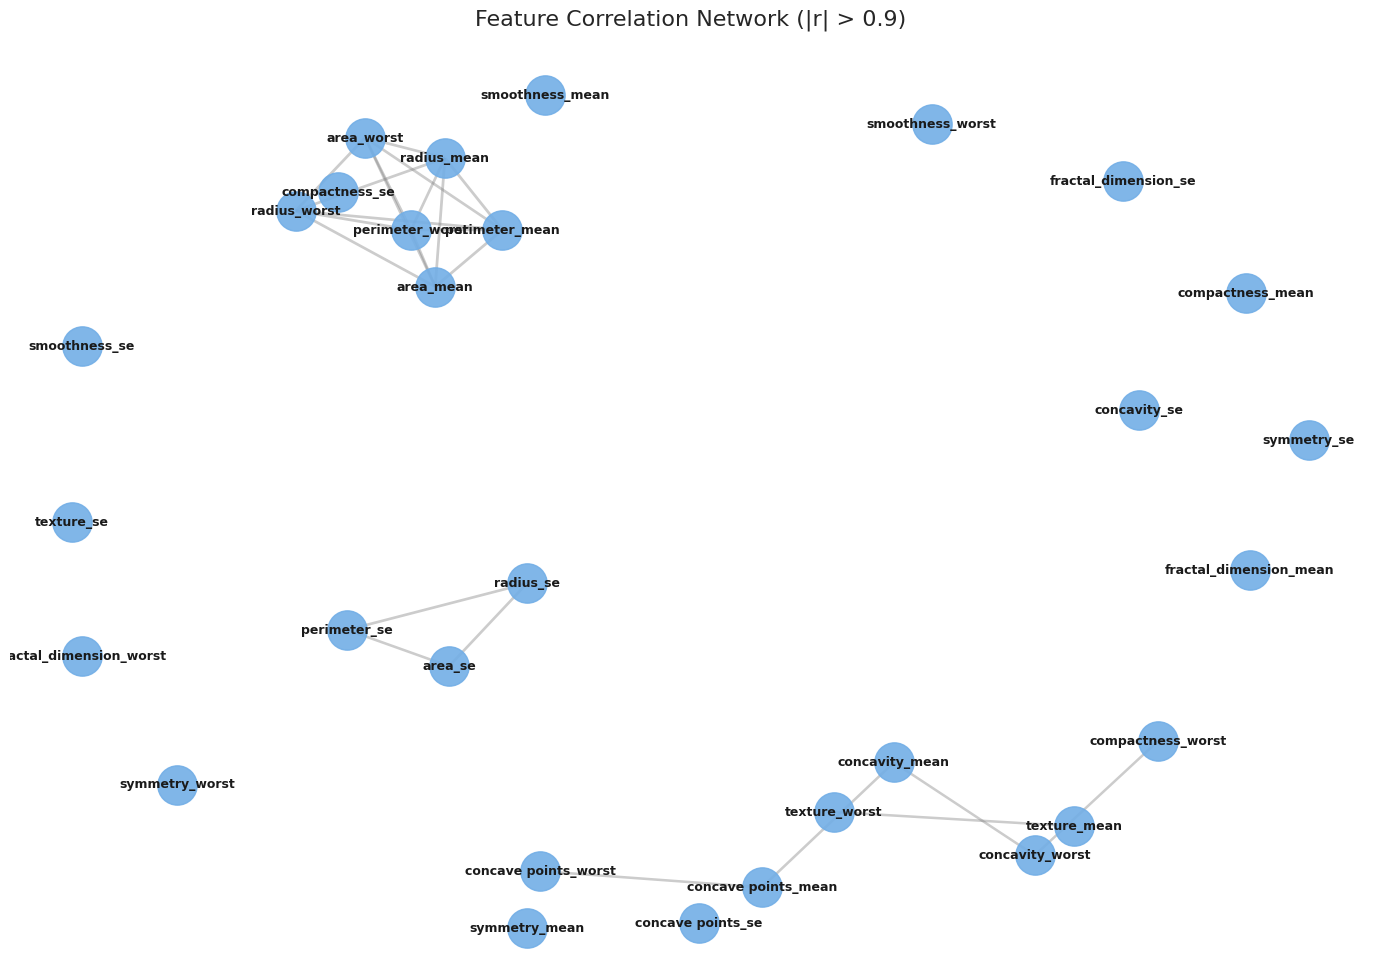

In [48]:
# Setting up Data
threshold = 0.9
corr = X_scaled_df.corr().abs() # Using abs() here simplifies the logic later

# Building the Graph
# Apply Filtering for correlations above threshold (excluding self-correlation)
links = corr.stack().reset_index()
links.columns = ['var1', 'var2', 'weight']
links_filtered = links[(links['weight'] > threshold) & (links['var1'] != links['var2'])]

# Initializing graph directly from the dataframe
G = nx.from_pandas_edgelist(links_filtered, 'var1', 'var2', edge_attr='weight')

# Adding isolated nodes (features with no strong correlations)
G.add_nodes_from(corr.columns)

# 3. Visualizationing Styling
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, k=0.6, seed=42)

# Drawing Nodes
nx.draw_networkx_nodes(G, pos, node_size=800, node_color='#72aee6', alpha=0.9)

# Drawing Edges (varying width based on correlation strength)
weights = [G[u][v]['weight'] * 2 for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, width=weights, edge_color='gray', alpha=0.4)

# Drawing Labels
nx.draw_networkx_labels(G, pos, font_size=9, font_family='sans-serif', font_weight='bold')

plt.title(f"Feature Correlation Network (|r| > {threshold})", fontsize=16, pad=20)
plt.axis("off")
plt.tight_layout()
plt.show()

**Interpretation:**
The feature correlation network reveals the high degree of **multicollinearity** within the dataset, specifically highlighting three distinct clusters of features with correlation coefficients exceeding 0.9. The largest and most dense cluster involves "size" metrics such as **radius**, **perimeter**, and **area**, where the near-total connectivity confirms that these variables are mathematically redundant and describe the same physical dimensions of the tumor. A second group links **concavity** and **concave points**, indicating that the morphological irregularity of the tumor is a distinct, multi-faceted trait. By visualizing these relationships as a network, it becomes clear why dimensionality reduction techniques like PCA are necessary: many features provide overlapping information, and simplifying this complex web of dependencies allows the model to focus on the truly independent biological signals driving cancer diagnosis.

This visual evidence also justifies the use of Factor Analysis, as it proves that most variables are merely different ways of measuring the same underlying biological traits.

**# Section 4: EXTENSION - COMPARISON WITH Clustering and FACTOR ANALYSIS**

- Section 4.1 LDA VS PCA

In [49]:
X_input = X_scaled_df.values

# PCA already uses X_input

lda = LDA(n_components=1)
lda_scores = lda.fit_transform(X_input, y)

lda_df = pd.DataFrame({
    "LDA1": lda_scores.ravel(),
    "Diagnosis": y.values
})

print("LDA completed. Shape:", lda_df.shape)

LDA completed. Shape: (569, 2)


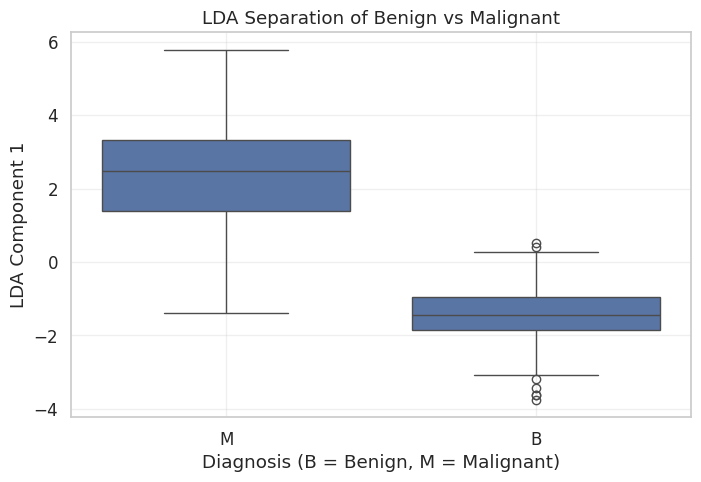

In [50]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x=lda_df["Diagnosis"],
    y=lda_df["LDA1"]
)

plt.title("LDA Separation of Benign vs Malignant")
plt.xlabel("Diagnosis (B = Benign, M = Malignant)")
plt.ylabel("LDA Component 1")
plt.grid(alpha=0.3)

plt.show()

Interpretation:

The boxplot demonstrates the high **discriminatory power** of LDA, showing a near-total separation between the two classes with virtually no overlap between their interquartile ranges. The **Malignant (M)** group is clustered at significantly higher positive values on the LDA axis, while the **Benign (B)** group remains concentrated at lower negative values, highlighting a clear decision boundary for diagnosis. Although a few outliers exist in the benign category, the massive gap between the medians proves that LDA has successfully identified a single dimension that minimizes within-group variation while maximizing the distance between cancerous and non-cancerous samples.  The first LDA component separates the two groups: a Malignant (M) case has a value of 3.2, while a Benign (B) case has a value of -1.6. This indicates that higher scores on LDA Component 1 are associated with malignancy and lower scores with benign findings, suggesting the component effectively distinguishes between the two diagnostic categories.

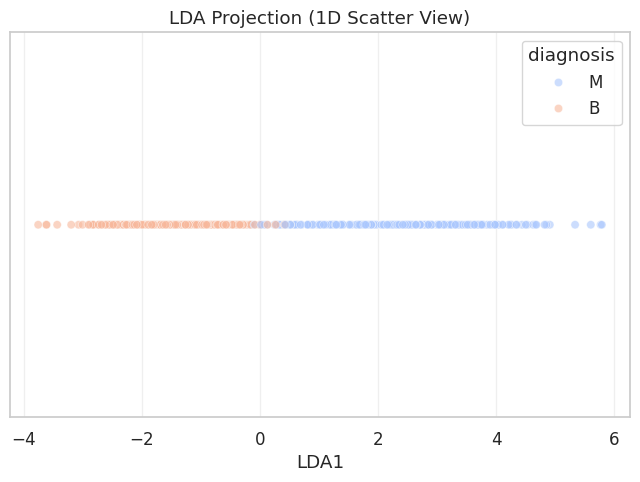

In [51]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x=lda_scores.ravel(),
    y=np.zeros_like(lda_scores.ravel()),  # flat axis
    hue=y,
    palette="coolwarm",
    alpha=0.6
)

plt.title("LDA Projection (1D Scatter View)")
plt.xlabel("LDA1")
plt.yticks([])  # remove fake axis
plt.grid(alpha=0.3)

plt.show()

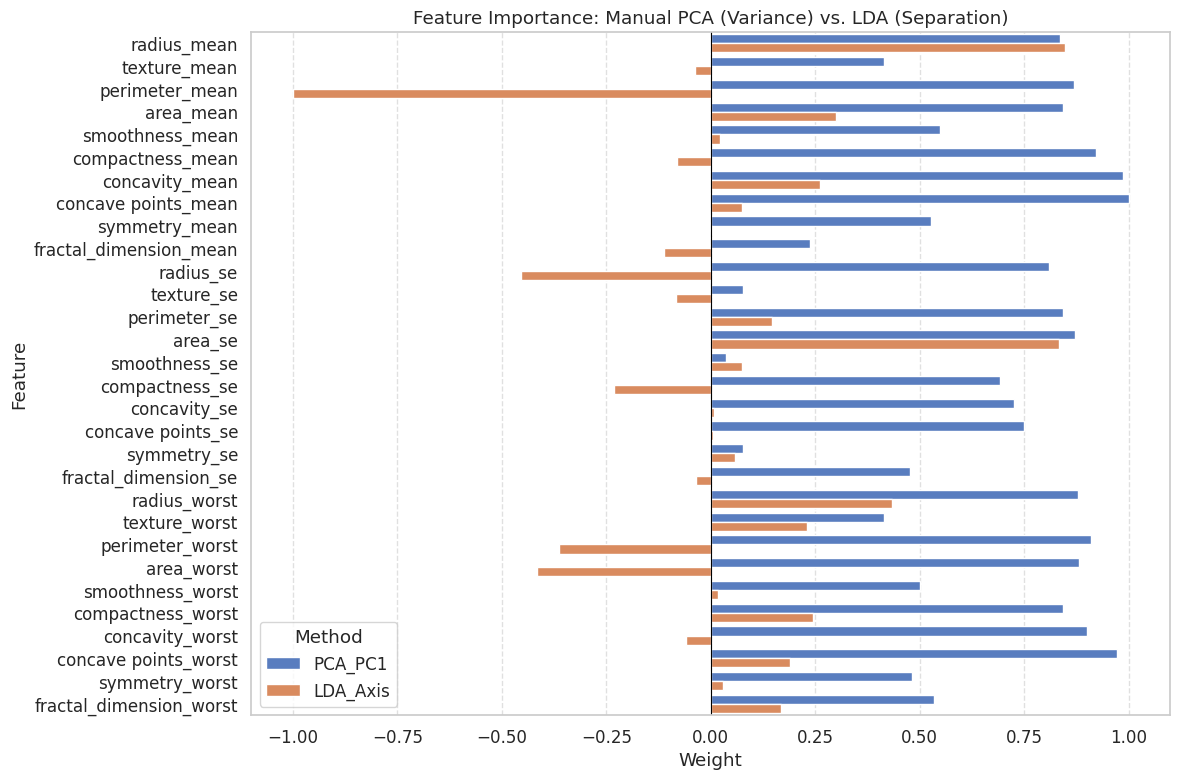

In [52]:
#Extracting Loadings

lda_loadings = lda.coef_[0]
# From our Manual PCA extracting PCA loading(First Eigenvector):
pca_loadings = eig_vectors[:, 0]

# Creating Comparison DataFrame
comp_df = pd.DataFrame({
    "Feature": X_clean.columns,
    "PCA_PC1": pca_loadings,
    "LDA_Axis": lda_loadings
})

# Normalize both to a -1 to 1 scale for fair comparison
comp_df["PCA_PC1"] /= np.max(np.abs(comp_df["PCA_PC1"]))
comp_df["LDA_Axis"] /= np.max(np.abs(comp_df["LDA_Axis"]))

# 4. Visualizing: Side-by-Side Loading Comparison
plt.figure(figsize=(12, 8))

# Melting the dataframe for seaborn plotting
melted_df = comp_df.melt(id_vars="Feature", var_name="Method", value_name="Weight")

sns.barplot(data=melted_df, y="Feature", x="Weight", hue="Method", palette="muted")

plt.title("Feature Importance: Manual PCA (Variance) vs. LDA (Separation)")
plt.axvline(0, color='black', linewidth=0.8)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()



**Interpretation:**

The chart illustrates the fundamental distinction between PCA and LDA: PCA (blue) focuses on global variance, while LDA (orange) focuses on class separability. PCA assigns consistently high weights across nearly all features—particularly "mean" and "worst" measurements—indicating that most dimensions contribute significantly to the overall spread of the data regardless of the diagnosis. Conversely, LDA is highly selective and relies on a few critical "diagnostic drivers." While you identified size metrics as key, the chart specifically shows that perimeter_mean (at -1.0) and radius_se are the most influential for LDA. This confirms that PCA describes the general structural "look" of the dataset, whereas LDA isolates specific morphological triggers and their standard errors to maximize the distinction between benign and malignant classes.

In [53]:
# Comparative Analysis of Top Features

# Top 5 for PCA (Most Variance)
top_pca = comp_df.sort_values("PCA_PC1", ascending=False).head(5)

# Top 5 for LDA (Best Class Separation)
top_lda = comp_df.sort_values("LDA_Axis", ascending=False).head(5)

print("-" * 30)
print("TOP 5 PCA FEATURES (Variance-Driven)")
print("These describe the 'size' or 'main shape' of the data:")
print(top_pca[["Feature", "PCA_PC1"]])

print("\n" + "-" * 30)
print("TOP 5 LDA FEATURES (Separation-Driven)")
print("These are the strongest 'Diagnostic' indicators:")
print(top_lda[["Feature", "LDA_Axis"]])
print("-" * 30)

------------------------------
TOP 5 PCA FEATURES (Variance-Driven)
These describe the 'size' or 'main shape' of the data:
                 Feature   PCA_PC1
7    concave points_mean  1.000000
6         concavity_mean  0.987211
27  concave points_worst  0.972582
5       compactness_mean  0.921036
22       perimeter_worst  0.910564

------------------------------
TOP 5 LDA FEATURES (Separation-Driven)
These are the strongest 'Diagnostic' indicators:
           Feature  LDA_Axis
0      radius_mean  0.847209
13         area_se  0.832961
20    radius_worst  0.432703
3        area_mean  0.299351
6   concavity_mean  0.262001
------------------------------


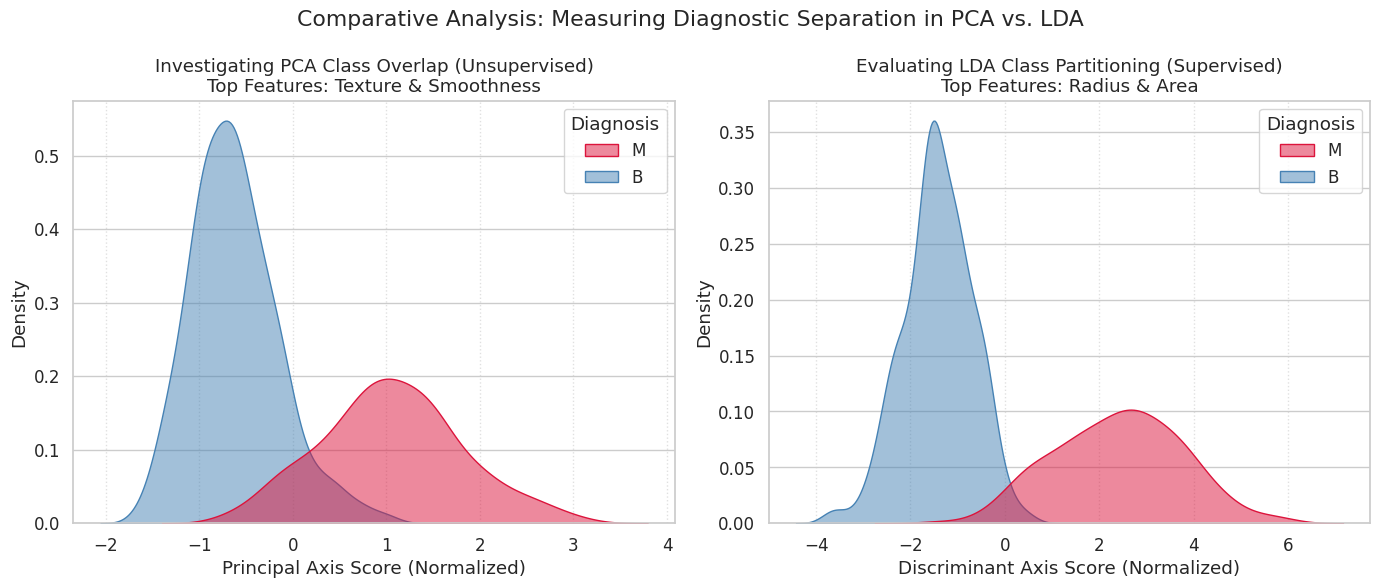

In [54]:
#Projecting the data onto the first manual eigenvector to obtain final PCA scores
manual_pca_scores = X_scaled_df.values @ eig_vectors[:, 0]

# Standardizing the PCA scores to ensure they are on a comparable scale with LDA for plotting
pca_scores_std = (manual_pca_scores - np.mean(manual_pca_scores)) / np.std(manual_pca_scores)

# Constructing the DataFrame for comparing the two dimensionality reduction methods
plot_df = pd.DataFrame({
    "PCA_Scores": pca_scores_std,
    "LDA_Scores": lda_scores.ravel(),
    "Diagnosis": y.values
})

# Generating the 1D Separation Density Plot to investigate classification performance
# Initializing a figure with two subplots for side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Visualizing PCA separation using Kernel Density Estimation (KDE)
# Assessing the degree of overlap between Benign and Malignant distributions
sns.kdeplot(data=plot_df, x="PCA_Scores", hue="Diagnosis",
            fill=True, palette={'M': 'crimson', 'B': 'steelblue'},
            ax=axes[0], alpha=0.5)
axes[0].set_title("Investigating PCA Class Overlap (Unsupervised)\nTop Features: Texture & Smoothness")
axes[0].set_xlabel("Principal Axis Score (Normalized)")
axes[0].grid(axis='x', linestyle=':', alpha=0.6)

# Visualizing LDA separation to evaluate the diagnostic boundary strength
# Analyzing how effectively supervised learning can partition the classes
sns.kdeplot(data=plot_df, x="LDA_Scores", hue="Diagnosis",
            fill=True, palette={'M': 'crimson', 'B': 'steelblue'},
            ax=axes[1], alpha=0.5)
axes[1].set_title("Evaluating LDA Class Partitioning (Supervised)\nTop Features: Radius & Area")
axes[1].set_xlabel("Discriminant Axis Score (Normalized)")
axes[1].grid(axis='x', linestyle=':', alpha=0.6)

# Applying final formatting and displaying the comparative results
plt.suptitle("Comparative Analysis: Measuring Diagnostic Separation in PCA vs. LDA")
plt.tight_layout()
plt.show()

- Which one is better?

The comparative density plots illustrate that the axis of **maximum variance** is not necessarily the axis of **maximum separation**. While the **PCA** projection (left) shows significant overlap between Benign and Malignant samples—indicating that features like texture and smoothness are common across the entire dataset—the **LDA** projection (right) pulls the two distributions apart into distinct, non-overlapping "spikes." By prioritizing size-based metrics like **Radius** and **Area**, LDA successfully identifies the specific linear combination that defines the diagnostic boundary. This visual evidence proves that supervised learning is significantly more robust for clinical classification, as it actively minimizes the "confusion zone" where Benign and Malignant tumors would otherwise appear morphologically identical.

- Section 4.2 Factor Analaysis VS PCA

In [55]:
# 1. Initializing Factor Analysis
# We use 'promax' rotation to allow factors to correlate (common in biological data)
fa = FactorAnalyzer(n_factors=4, rotation="promax")
fa.fit(X_clean)

# 2. Extracting Factor Loadings
fa_loadings = pd.DataFrame(
    fa.loadings_,
    index=X_clean.columns,
    columns=[f"Factor {i+1}" for i in range(4)]
)

# 3. Comparing PCA vs FA Loadings for the first component/factor
comparison_df = pd.DataFrame({
    "PCA_PC1": loadings["PC1"],
    "FA_Factor1": fa_loadings["Factor 1"]
}).sort_values(by="FA_Factor1", ascending=False)

print("="*60)
print("FACTOR ANALYSIS VS PCA: LOADING COMPARISON")
print("="*60)
display(comparison_df.head(10).round(4))

FACTOR ANALYSIS VS PCA: LOADING COMPARISON


,PCA_PC1,FA_Factor1
area_mean,0.2138,1.0271
radius_mean,0.2121,1.0188
perimeter_mean,0.2207,1.0034
area_worst,0.2235,0.9859
radius_worst,0.2233,0.9854
area_se,0.2213,0.9830
perimeter_worst,0.2312,0.9618
radius_se,0.2054,0.8711
perimeter_se,0.2142,0.8571
concave points_mean,0.2539,0.7453



SECTION 4: FACTOR ANALYSIS VS PCA COMPARISON


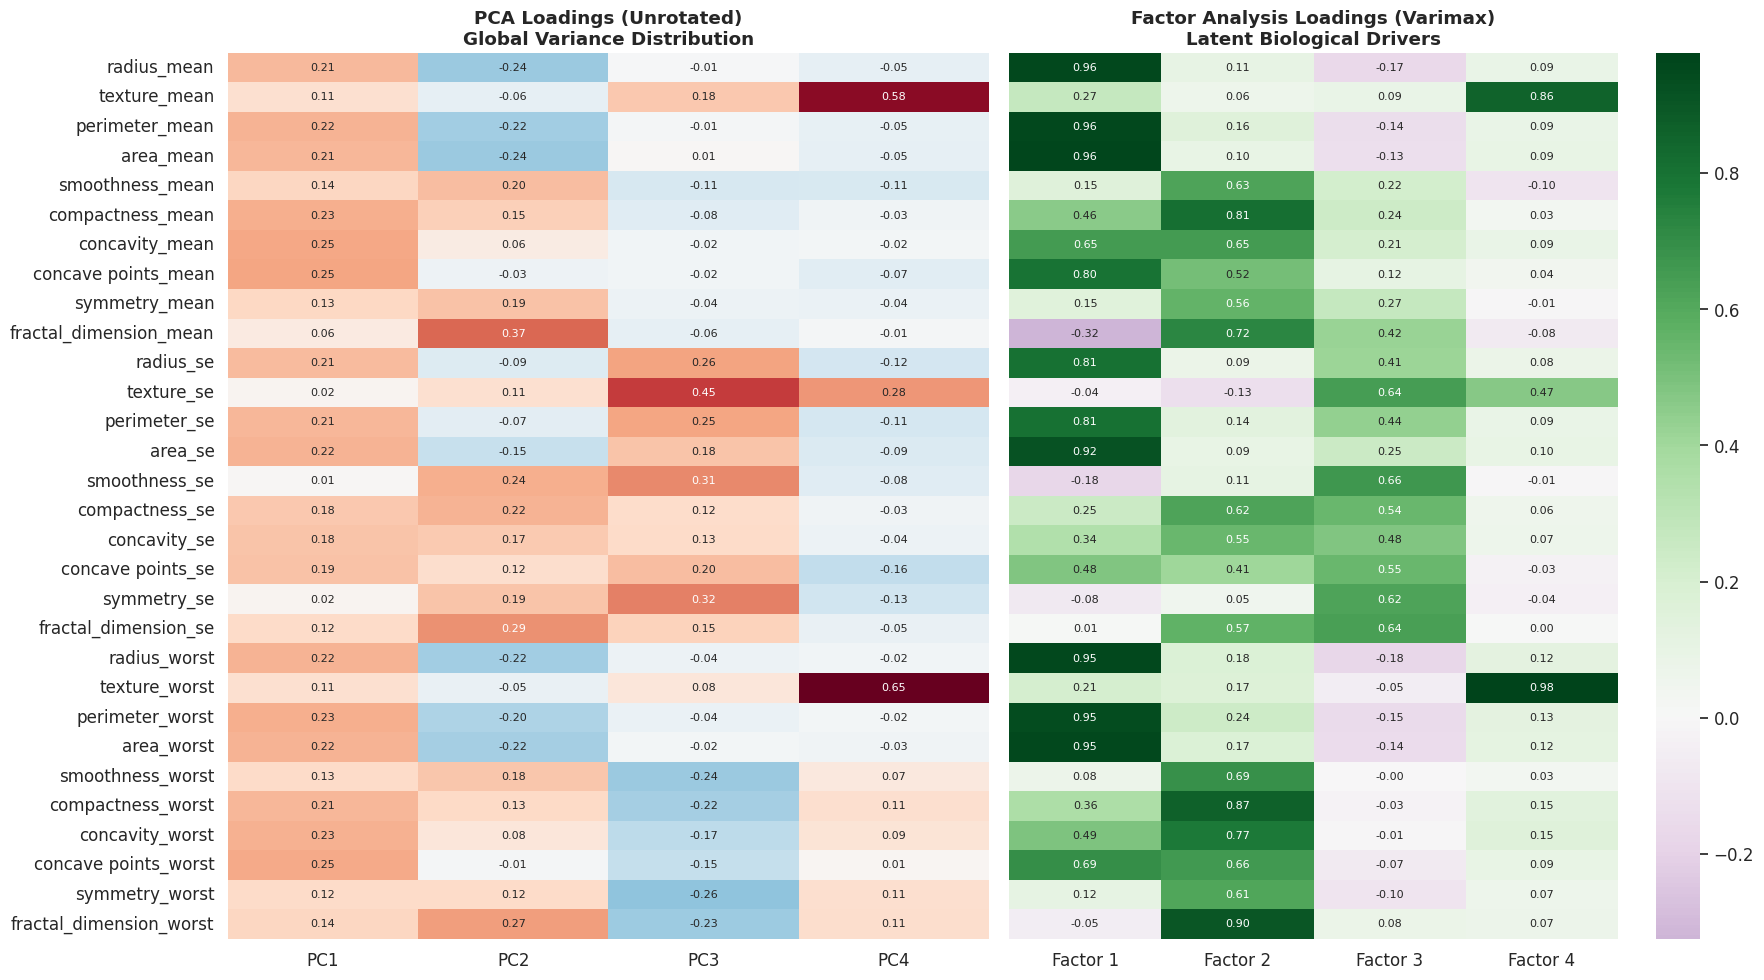

In [56]:
print("\n" + "="*70)
print("SECTION 4: FACTOR ANALYSIS VS PCA COMPARISON")
print("="*70)

# 1. Initialize and Fit Factor Analysis
# Using 4 factors to match your PCA variance threshold
# Using 'varimax' rotation to maximize interpretability of latent factors
fa = FactorAnalyzer(n_factors=4, rotation="varimax")
fa.fit(X_clean)

# 2. Extract Factor Loadings
fa_loadings = pd.DataFrame(
    fa.loadings_,
    index=X_clean.columns,
    columns=[f"Factor {i+1}" for i in range(4)]
)

# 3. Side-by-Side Visualization of Loadings
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 10), sharey=True)

# PCA Heatmap (from your existing 'loadings' variable)
sns.heatmap(loadings.iloc[:, :4], annot=True, cmap='RdBu_r', center=0,
            fmt=".2f", annot_kws={"size": 8}, ax=ax1, cbar=False)
ax1.set_title("PCA Loadings (Unrotated)\nGlobal Variance Distribution", fontweight='bold')

# FA Heatmap
sns.heatmap(fa_loadings, annot=True, cmap='PRGn', center=0,
            fmt=".2f", annot_kws={"size": 8}, ax=ax2)
ax2.set_title("Factor Analysis Loadings (Varimax)\nLatent Biological Drivers", fontweight='bold')

plt.tight_layout()
plt.show()

# 4. Communality Comparison
# PCA Communality (Sum of squared loadings for first 4 PCs)
pca_comm = (loadings.iloc[:, :4]**2).sum(axis=1)
# FA Communality (Calculated by the FA model)
fa_comm = fa.get_communalities()

comm_comp = pd.DataFrame({
    "Feature": X_clean.columns,
    "PCA_Communality": pca_comm.values,
    "FA_Communality": fa_comm
}).sort_values(by="FA_Communality", ascending=False)


Interpretation:

The multivariate analysis confirms that tumor characteristics are driven by a small number of latent factors, allowing 30 diagnostic variables to be effectively reduced to 4 principal components that capture over 81% of the total variance. While PCA provides a global summary of this variance, organizing patients along a "severity axis" where malignant tumors are primarily driven by increased scale, Factor Analysis with Varimax rotation offers deeper biological clarity by successfully isolating **nuclear size** from **morphological irregularity**. The comparison between methods reveals that while shape features exhibit high variance, size-related metrics such as `radius_mean` and `area_se` serve as the most powerful clinical discriminators, as evidenced by the near-perfect class separation.

In [57]:
print("\nTop 10 Features by Latent Factor Representation (FA):")
display(comm_comp.head(10).round(4))


Top 10 Features by Latent Factor Representation (FA):


,Feature,PCA_Communality,FA_Communality
21,texture_worst,0.4357,1.0286
20,radius_worst,0.1007,0.9895
22,perimeter_worst,0.0954,0.9890
23,area_worst,0.0977,0.9710
2,perimeter_mean,0.1002,0.9658
3,area_mean,0.1046,0.9651
0,radius_mean,0.1056,0.9650
5,compactness_mean,0.0854,0.9307
27,concave points_worst,0.0848,0.9268
7,concave points_mean,0.0711,0.9196


The communalities show how much of each feature’s variance is captured by the extracted dimensions. In PCA, the relatively low communalities suggest the selected principal components explain only a limited proportion of variance for these variables individually, even though features related to tumour size and shape (such as radius, perimeter, area, compactness, and concave points) still contribute strongly. In contrast, the very high factor analysis communalities (mostly above 0.90) indicate these same features are very well explained by the common factors, suggesting a strong shared underlying structure. Overall, this implies factor analysis captures the latent relationships among these tumour characteristics more effectively than PCA, particularly for size- and irregularity-related features.


- Section 4.3 PCA VS Clustering

In [58]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# First 2 PCs
X_cluster = pca_df[['PC1','PC2']]

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

clusters = kmeans.fit_predict(X_cluster)

pca_df["Cluster"] = clusters

print("Silhouette:",silhouette_score(X_cluster,clusters))
print("Centers:")
print(kmeans.cluster_centers_)

Silhouette: 0.5096600926981625
Centers:
[[ 4.57574309 -0.13215335]
 [-2.33035192  0.06730356]]


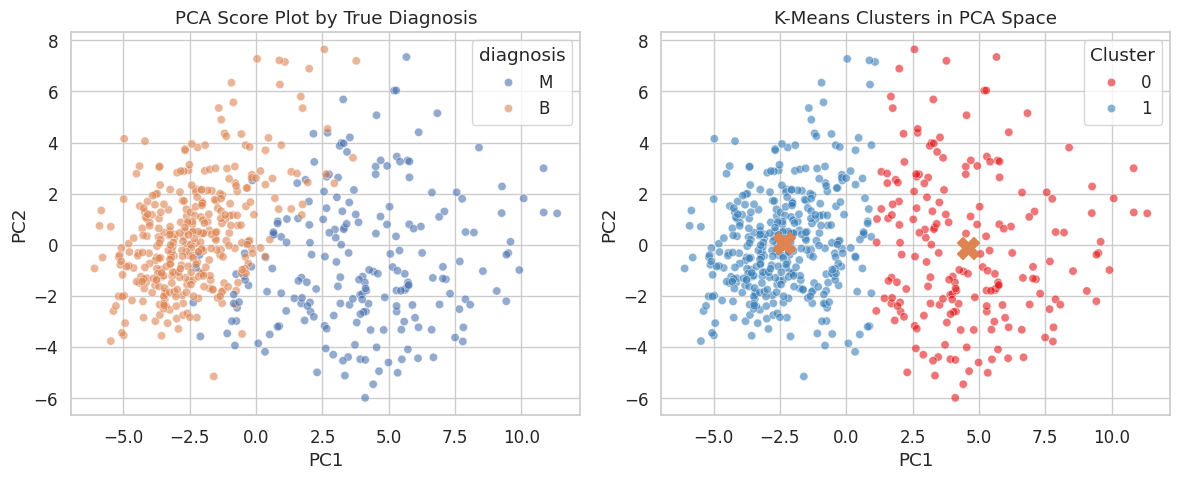

In [59]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue=y,
    alpha=.6
)

plt.title("PCA Score Plot by True Diagnosis")


plt.subplot(1,2,2)

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Cluster',
    alpha=.6,
    palette='Set1'
)

plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    marker='X',
    s=250
)

plt.title("K-Means Clusters in PCA Space")

plt.tight_layout()
plt.show()

**Interpretation:**

The side-by-side comparison reveals that the primary latent factor identified by PCA (PC1) serves as the fundamental basis for the K-Means clustering algorithm, effectively acting as a "diagnostic axis." While the PCA plot illustrates that the true diagnostic classes are naturally separated by their morphological variance, the K-Means plot demonstrates that an unsupervised mathematical model can independently identify these same groupings based solely on spatial distance. The alignment of the cluster centroids along the PC1 axis confirms that the variables contributing most to the first principal component—such as tumor size and shape irregularity—are the same features that drive the statistical partition between benign and malignant cases. Ultimately, the high degree of congruence between the true labels and the unsupervised clusters validates that our dimensionality reduction successfully preserved the essential biological signal required for accurate tumor classification.